# Tarea 1: artículos violados a partir de los hechos

**Problema.** Clasificación multietiqueta. A partir del texto de la sección **Hechos** de cada sentencia de fondo de la Corte IDH, se predice qué artículos de la Convención Americana declara violados la sentencia. Las etiquetas salen de los puntos resolutivos con la regla de la Entrega 1, corregida (ver `CAMBIOS.md`, sección 11). El modelo nunca ve el fondo ni los resolutivos, que contienen la respuesta.

- **Datos:** 305 sentencias, una por caso. Se usan los 15 artículos declarados violados en al menos 25 sentencias. Conjunto y particiones de `clasificacion/` (`comun.py`).
- **Validación:**
  - 5 particiones fijas con estratificación multietiqueta.
  - Los hiperparámetros y los umbrales se eligen dentro del entrenamiento de cada partición (validación anidada).
  - Prueba temporal: entrenar hasta 2018 y evaluar con las sentencias de 2019 en adelante.
- **Métricas:** las principales son el F1 macro y la AP macro (precisión promedio), porque pesan igual los 15 artículos. El F1 micro, la pérdida de Hamming y la exactitud estricta (acertar la lista completa) complementan.

**Cómo ejecutarlo.** De arriba abajo, desde la carpeta del proyecto (o con `CORTEIDH_BASE` definida). Tarda unos 9 minutos con GPU; las celdas más lentas son las de spaCy (entidades) y los embeddings e5. Las tablas quedan en `procesado/clasificacion/resultados/t1_*.csv` y las figuras en `procesado/figuras/c0*_t1_*.png`.

**Contenido.**
- Secciones 1 a 9: el recorrido, un cambio a la vez.
- Secciones 10 a 13: el modelo final, que junta las mejoras con un protocolo único, y su análisis.
- Sección 14: conclusiones.

In [1]:
import os, sys
from pathlib import Path

# Carpeta del proyecto: la del notebook, salvo que CORTEIDH_BASE ya esté definida (por ejemplo, en Colab)
os.environ.setdefault("CORTEIDH_BASE", str(Path.cwd()))
sys.path.append("clasificacion")
from comun import *

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PALETA = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
DIR_FIGURAS = BASE_DIR / "procesado" / "figuras"


def guardar_fig(fig, nombre):
    """Guarda la figura en procesado/figuras/ (prefijo c: figuras de la Entrega 2)."""
    DIR_FIGURAS.mkdir(parents=True, exist_ok=True)
    fig.savefig(DIR_FIGURAS / f"{nombre}.png", dpi=150, bbox_inches="tight")

# 1. Conocer los datos

In [2]:
df, Y, etiquetas = cargar_articulos()
print(df.shape, Y.shape)

df.head(3)

(305, 27) (305, 15)


,doc_id,caso_id,titulo,estado,anio,tipo_sentencia,articulos,texto,lemas,num_palabras,...,art_17,art_19,art_21,art_22,art_23,art_24,art_25,art_26,temporal,particion
0,1034838366_sentencia,caso cuéllar sandoval y otros vs el salvador,caso cuéllar sandoval y otros vs. el salvador,el salvador,2024.0,fondo,"[3, 4, 5, 7, 8, 13, 16, 17, 19, 25]","En este capítulo, la Corte establecerá los hec...",capítulo corte establecer caso base reconocimi...,2900,...,1,1,0,0,0,0,1,0,prueba,1
1,1035032346_sentencia,caso aguirre magaña vs el salvador,caso aguirre magaña vs. el salvador,el salvador,2024.0,fondo,"[8, 25]",Conforme al reconocimiento de responsabilidad ...,conforme reconocimiento responsabilidad estado...,412,...,0,0,0,0,0,0,1,0,prueba,2
2,1039244171_sentencia,caso asociación civil memoria activa vs argentina,caso asociación civil memoria activa vs. argen...,argentina,2024.0,fondo,"[4, 5, 8, 13, 24, 25]","En este capítulo, la Corte establecerá los hec...",capítulo corte establecer caso base reconocimi...,7794,...,0,0,0,0,0,1,1,0,prueba,0


In [3]:
# ¿Qué tan frecuente es cada artículo? (de más a menos frecuente)
prevalencia = pd.Series(Y.mean(axis=0), index=etiquetas).sort_values(ascending=False)
prevalencia

8     0.931148
25    0.800000
5     0.675410
4     0.445902
7     0.429508
13    0.206557
19    0.203279
11    0.186885
3     0.170492
26    0.154098
17    0.154098
24    0.140984
22    0.134426
21    0.127869
23    0.114754
dtype: float64

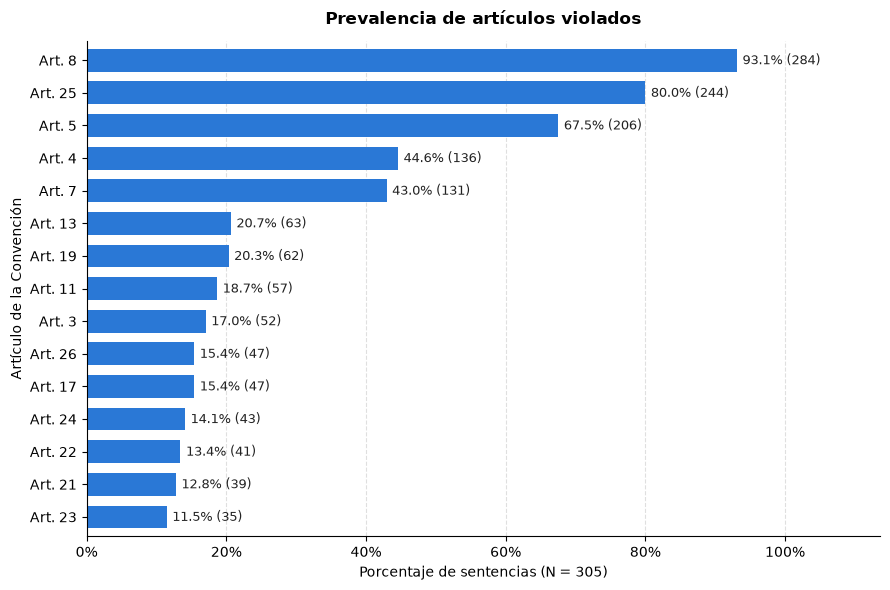

In [4]:
from matplotlib.ticker import PercentFormatter

idx = [f"Art. {a}" for a in etiquetas]
prev = pd.Series(Y.mean(0), index=idx).sort_values()
conteos = pd.Series(Y.sum(0), index=idx)[prev.index]

ax = prev.plot.barh(figsize=(9, 6), color=PALETA[0], width=0.7, xlim=(0, prev.max() * 1.22),
                    xlabel=f"Porcentaje de sentencias (N = {len(Y)})", ylabel="Artículo de la Convención")
ax.set_title("Prevalencia de artículos violados", pad=12, fontweight="bold")
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.bar_label(ax.containers[0], labels=[f"{p:.1%} ({n})" for p, n in zip(prev, conteos)], padding=4, fontsize=9,
             color="#222222")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)
plt.tight_layout()
guardar_fig(ax.figure, "c01_t1_prevalencia")
plt.show()

In [5]:
# ¿Cuántos artículos tiene cada sentencia?
print("Artículos por sentencia (media):", round(Y.sum(axis=1).mean(), 2))

# ¿Qué tan largos son los hechos? (palabras)
df["num_palabras"].describe()

Artículos por sentencia (media): 4.88


count      305.000000
mean      5408.396721
std       3625.493539
min        412.000000
25%       2912.000000
50%       4562.000000
75%       6992.000000
max      31830.000000
Name: num_palabras, dtype: float64

In [6]:
# ¿Qué artículos aparecen juntos? (matriz de co-ocurrencia: número de sentencias con los dos)
co = pd.DataFrame(Y.T @ Y, index=etiquetas, columns=etiquetas)
co.style.background_gradient(cmap="Blues")

,3,4,5,7,8,11,13,17,19,21,22,23,24,25,26
3,52,44,50,49,50,17,17,21,17,7,13,3,8,49,2
4,44,136,131,77,130,31,33,36,48,14,25,6,20,121,19
5,50,131,206,116,194,53,46,47,62,20,36,13,31,177,30
7,49,77,116,131,128,43,30,31,30,15,22,7,21,109,14
8,50,130,194,128,284,55,58,46,58,36,39,34,41,235,42
11,17,31,53,43,55,57,17,20,22,13,15,5,20,49,14
13,17,33,46,30,58,17,63,22,23,10,18,15,14,52,16
17,21,36,47,31,46,20,22,47,37,8,24,3,8,43,8
19,17,48,62,30,58,22,23,37,62,11,25,6,10,56,11
21,7,14,20,15,36,13,10,8,11,39,10,8,4,36,11


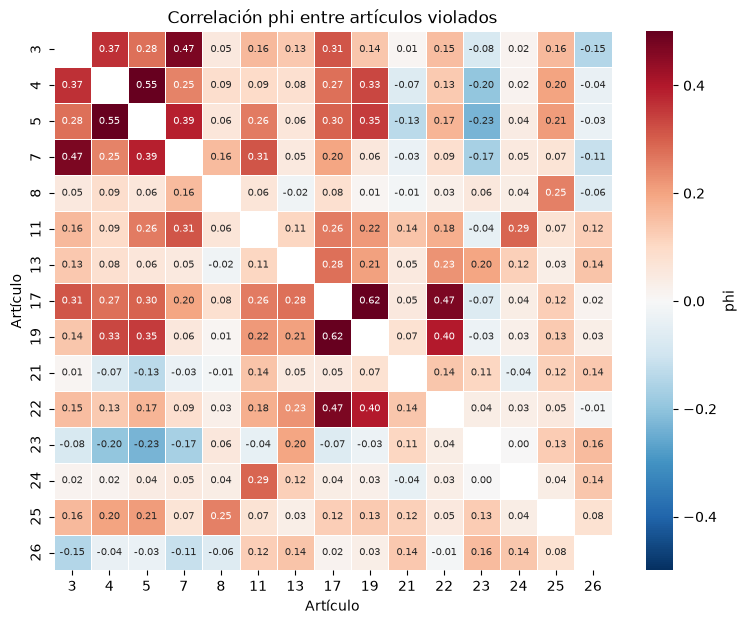

In [7]:
# Correlación phi (Pearson entre columnas binarias): si dos artículos aparecen juntos más de lo que
# se esperaría por lo frecuente que es cada uno. La diagonal se llena antes de crear el DataFrame:
# en pandas 3, DataFrame.values puede ser de solo lectura y np.fill_diagonal fallaría.
matriz = np.corrcoef(Y, rowvar=False)
np.fill_diagonal(matriz, np.nan)
phi = pd.DataFrame(matriz, index=etiquetas, columns=etiquetas)

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(phi, ax=ax, cmap="RdBu_r", vmin=-0.5, vmax=0.5, center=0, annot=True, fmt=".2f",
            annot_kws={"size": 7}, linewidths=0.5, linecolor="white", cbar_kws={"label": "phi"})
ax.set(title="Correlación phi entre artículos violados", xlabel="Artículo", ylabel="Artículo")
guardar_fig(fig, "c02_t1_phi")
plt.show()

**Phi.** La co-ocurrencia cruda está dominada por los artículos 8 y 25, presentes en el 93 % y el 80 % de las sentencias. Phi descuenta lo frecuente que es cada artículo: el par 8–25 baja a φ = 0,25. Aparecen tres bloques claros:

- **Familia, niñez y circulación (17–19–22).** φ = 0,62 entre 17 y 19, 0,47 entre 17 y 22, y 0,40 entre 19 y 22. Corresponde a los casos de desplazamiento y migración que afectan a familias y niños.
- **Vida e integridad (4–5).** φ = 0,55: ejecuciones, tortura y uso de la fuerza.
- **Desaparición forzada (3–7, y 3–4).** φ = 0,47 entre 3 y 7, y 0,37 entre 3 y 4: personalidad jurídica, libertad y vida.

El artículo 23 (derechos políticos) es el más aislado: tiene correlación negativa con 4, 5 y 7 (φ entre −0,17 y −0,23).

Phi es descriptivo: no prueba causalidad, y su valor máximo depende de la prevalencia de los dos artículos.

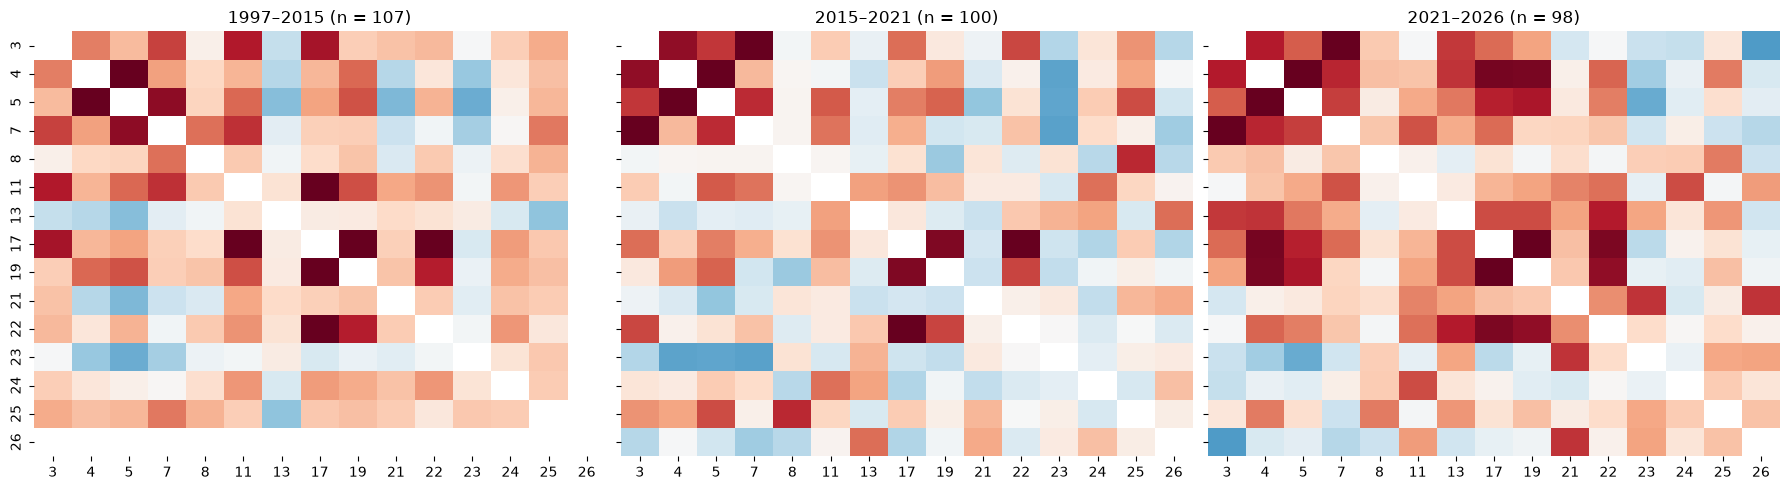

,1997–2015,2015–2021,2021–2026
3,14,18,20
4,49,42,45
5,71,63,72
7,45,43,43
8,97,95,92
11,15,22,20
13,9,14,40
17,8,10,29
19,18,13,31
21,22,7,10


In [8]:
# ¿Cambian con el tiempo? La misma matriz en tres periodos con el mismo número de sentencias
etapas = pd.qcut(df["anio"], q=3)
nombres = [f"{int(np.ceil(p.left))}–{int(p.right)}" for p in etapas.cat.categories]
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
for ax, periodo, nombre in zip(axes, etapas.cat.categories, nombres):
    idx = np.flatnonzero(etapas == periodo)
    with np.errstate(invalid="ignore"):          # el art. 26 no tiene positivos en el primer periodo
        m = np.corrcoef(Y[idx], rowvar=False)
    np.fill_diagonal(m, np.nan)
    sns.heatmap(m, ax=ax, cmap="RdBu_r", vmin=-0.5, vmax=0.5, center=0, cbar=False,
                xticklabels=etiquetas, yticklabels=etiquetas)
    ax.set_title(f"{nombre} (n = {len(idx)})")
plt.tight_layout()
plt.show()

# Una correlación calculada con pocos positivos es muy inestable: sentencias con cada artículo por periodo
conteo_periodo = pd.DataFrame(Y, columns=etiquetas).groupby(etapas.cat.codes.to_numpy()).sum().T
conteo_periodo.columns = nombres
conteo_periodo

**Phi por periodo.** Cada periodo tiene unas 100 sentencias, y la tabla de abajo cuenta los positivos de cada artículo. Con menos de 15 positivos, un par de sentencias puede cambiar el signo de una correlación. Por eso solo se leen los cambios grandes y con conteos suficientes:

- **Desaparición forzada (3–7).** La asociación pasa de 0,34 a 0,54 y luego a 0,52: sube después de 2015 y se mantiene.
- **Libertad de expresión (13).** Es el cambio más claro. Pasa de 9 sentencias a 40 y cambia de compañía. Antes de 2015 era negativo con 4 y 5 (−0,14 y −0,21). Desde 2021 es positivo con 4, 5 y 7 (0,36, 0,26 y 0,19). En los casos recientes, el 13 aparece en desapariciones y ejecuciones, como derecho a la verdad y acceso a la información, y no solo en casos de periodistas.
- **Propiedad y derechos políticos (21–23).** φ = 0,36 en el último periodo, pero con 10 y 18 positivos. Es una pista para revisar, no un hallazgo.
- **DESCA (26).** No tiene ningún positivo antes de 2015 (su fila queda vacía en el primer mapa). Esto anticipa el problema de la prueba temporal.

In [9]:
# Desplazamiento de etiquetas: proporción y número de sentencias con cada artículo
# en el entrenamiento temporal (hasta 2018) y en la prueba temporal (desde 2019)
cols = [f"art_{a}" for a in etiquetas]
prop, n = df.groupby("temporal")[cols].mean().T, df.groupby("temporal")[cols].sum().T
desplazamiento = pd.DataFrame({"sentencias_hasta_2018": n["entrenamiento"].to_numpy(),
                               "sentencias_desde_2019": n["prueba"].to_numpy(),
                               "proporcion_hasta_2018": prop["entrenamiento"].to_numpy(),
                               "proporcion_desde_2019": prop["prueba"].to_numpy()},
                              index=pd.Index(etiquetas, name="articulo"))
desplazamiento["razon"] = desplazamiento["proporcion_desde_2019"] / desplazamiento["proporcion_hasta_2018"]
desplazamiento.round(3).sort_values("razon", ascending=False)

,sentencias_hasta_2018,sentencias_desde_2019,proporcion_hasta_2018,proporcion_desde_2019,razon
articulo,,,,,
26,5,42,0.034,0.266,7.815
13,15,48,0.102,0.304,2.977
24,12,31,0.082,0.196,2.403
23,10,25,0.068,0.158,2.326
17,16,31,0.109,0.196,1.803
19,24,38,0.163,0.241,1.473
11,26,31,0.177,0.196,1.109
8,134,150,0.912,0.949,1.041
25,120,124,0.816,0.785,0.961


**Desplazamiento de etiquetas** (*label shift*: cambia la frecuencia de cada artículo entre el entrenamiento temporal, hasta 2018, y la prueba, desde 2019):

- **Art. 26 (DESCA).** Pasa del 3,4 % (5 sentencias) al 26,6 % (42). Con 5 ejemplos, el modelo temporal casi no tiene de dónde aprender.
- **Arts. 13, 24 y 23.** Su frecuencia se multiplica por 3,0, 2,4 y 2,3. Los dos primeros tienen 15 y 12 ejemplos de entrenamiento.
- **Núcleo clásico (8, 25, 5, 4, 7, 3).** Estable, con razones entre 0,9 y 1,04.
- **Arts. 21 y 22.** Bajan a la mitad o menos.

Esto es un cambio en la frecuencia, que el umbral fijo de 0,5 no tolera bien (sección 8). Otra cosa es el *concept drift*, en el que hechos parecidos reciben otra etiqueta según la época. Su ejemplo aparece en el análisis de errores (sección 13), con el artículo 26.

In [10]:
# Lee al menos tres textos completos
print(df.loc[0, "titulo"], df.loc[0, "articulos"])
print(df.loc[0, "texto"][:3000])

caso cuéllar sandoval y otros vs. el salvador [ 3  4  5  7  8 13 16 17 19 25]
En este capítulo, la Corte establecerá los hechos del caso con base en el reconocimiento de responsabilidad del Estado, el marco fáctico sometido a su conocimiento por la Comisión Interamericana, la prueba que obra en el expediente y los alegatos de las partes, en relación con los siguientes aspectos: (a) del contexto de desapariciones forzadas en el conflicto armado en El Salvador; (b) sobre Patricia Emilie Cuéllar Sandoval y su trabajo en la oficina del Socorro Jurídico Cristiano; (c) sobre la desaparición de Patricia Emilie Cuéllar Sandoval, Mauricio Cuéllar Cuéllar y Julia Orbelina Pérez, y (d) las acciones de investigación. A. Del contexto de desapariciones forzadas en el conflicto armado en El Salvador

Desde 1980 hasta 1991 El Salvador se vio sumido en un conflicto armado interno durante el cual se configuró el fenómeno de las desapariciones forzadas de personas. En efecto, a partir del año 1980 se pro

# 2. Línea base

In [11]:
filas_base = []
for k, ent, pru in iterar_particiones(df):
    P = np.tile(Y[ent].mean(axis=0), (len(pru), 1))      # la misma predicción para todas: la proporción de cada artículo
    filas_base.append({"modelo": "linea_base", "particion": k,
                       **metricas_multietiqueta(Y[pru], (P >= 0.5).astype(int), P)})
resumir(filas_base)

f1_micro         f1_macro         precision_micro          \
               mean     std     mean     std            mean     std   
modelo                                                                 
linea_base   0.6112  0.0087   0.1773  0.0036           0.803  0.0293   

           exhaustividad_micro         hamming         exactitud_estricta  \
                          mean     std    mean     std               mean   
modelo                                                                      
linea_base              0.4936  0.0067  0.2042  0.0045             0.0235   

                   ap_macro         ap_micro          
               std     mean     std     mean     std  
modelo                                                
linea_base  0.0224   0.3254  0.0138   0.6973  0.0269

**Línea base.** Ignora el texto y predice para todas las sentencias la proporción de cada artículo en el entrenamiento. Con umbral 0,5 marca siempre los artículos 8, 25 y 5.

- **F1 micro de 0,61.** Es engañosamente alto: se sostiene por el volumen de esos tres artículos.
- **F1 macro de 0,18.** Saca 0 en 12 de los 15 artículos.
- **AP macro de 0,33.** Es el valor de ordenar al azar.

Esta línea base fija el piso, y muestra por qué el F1 macro y la AP macro son las métricas que miden aprendizaje real.

# 3. Primer modelo: TF-IDF + regresión logística

In [12]:
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier

def tfidf_lr(C=1.0, ngramas=(1, 2), min_df=3):
    return make_pipeline(
        TfidfVectorizer(ngram_range=ngramas, min_df=min_df, max_df=0.9, sublinear_tf=True),
        OneVsRestClassifier(LogisticRegression(C=C, class_weight="balanced", max_iter=2000)))

def puntuar(modelo, X):
    """Puntajes y umbral: probabilidades con 0,5 si el modelo las da; si no, la distancia al hiperplano con 0."""
    if hasattr(modelo, "predict_proba"):
        return modelo.predict_proba(X), 0.5
    return modelo.decision_function(X), 0.0

def evaluar(nombre, crear_modelo, X):
    """Entrena y evalúa en las 5 particiones. crear_modelo es una función que devuelve un modelo nuevo."""
    filas = []
    for k, ent, pru in iterar_particiones(df):
        modelo = crear_modelo().fit(X[ent], Y[ent])
        P, umbral = puntuar(modelo, X[pru])
        filas.append({"modelo": nombre, "particion": k,
                      **metricas_multietiqueta(Y[pru], (P >= umbral).astype(int), P)})
    return filas

X = df["lemas"].to_numpy()
resultados = evaluar("tfidf_lr", tfidf_lr, X)
resumir(resultados)

f1_micro         f1_macro         precision_micro          \
             mean     std     mean     std            mean     std   
modelo                                                               
tfidf_lr   0.7582  0.0385   0.5796  0.0488          0.7862  0.0536   

         exhaustividad_micro         hamming         exactitud_estricta  \
                        mean     std    mean     std               mean   
modelo                                                                    
tfidf_lr              0.7329  0.0325  0.1517  0.0215             0.1527   

                 ap_macro        ap_micro          
             std     mean    std     mean     std  
modelo                                             
tfidf_lr  0.0754   0.6828  0.055   0.8502  0.0348

**TF-IDF + regresión logística** (lemas, unigramas y bigramas, `min_df=3`, `class_weight="balanced"`, C = 1, umbral 0,5):

- **F1 macro:** sube de 0,18 a 0,58.
- **AP macro:** sube de 0,33 a 0,68.
- **Exactitud estricta:** pasa del 2 % al 15 %.

`class_weight="balanced"` da más peso a los positivos de los artículos raros. Hay una brecha entre la AP (0,68) y el F1 (0,58): el modelo ordena bien las sentencias, pero el umbral fijo de 0,5 no es el mejor para todos los artículos. Las secciones 5 y 6 atacan esa brecha.

# 4. Preprocesamiento: la ablación

In [13]:
import spacy
nlp = spacy.load("es_core_news_sm", disable=["parser", "lemmatizer"])
nlp.max_length = 1_000_000

def tapar_entidades(texto, tipos=("PER", "LOC")):
    """Reemplaza nombres de personas y lugares por su tipo («PER», «LOC»)."""
    partes, fin = [], 0
    for e in nlp(texto).ents:
        if e.label_ in tipos:
            partes += [texto[fin:e.start_char], e.label_]
            fin = e.end_char
    return "".join(partes) + texto[fin:]

tapar_entidades("El 5 de mayo de 1992 Carlos Pérez fue detenido en Lima por agentes de la DINCOTE.")
# 'El 5 de mayo de 1992 PER fue detenido en LOC por agentes de la DINCOTE.'
X_ent = np.array([tapar_entidades(t) for t in df["texto"]], dtype=object)   # unos 2 minutos: guárdalo

In [14]:
filas = evaluar("lemas", tfidf_lr, X) + evaluar("texto crudo", tfidf_lr, df["texto"].to_numpy())
por_particion = pd.DataFrame(filas).pivot(index="particion", columns="modelo", values="f1_macro")
por_particion["lemas"] - por_particion["texto crudo"]

particion
0   -0.013970
1    0.008902
2    0.003396
3    0.018004
4    0.023793
dtype: float64

**Lemas frente a texto crudo.** La diferencia por partición va de −0,014 a +0,024, con una media de +0,008 a favor de los lemas. Es pequeña y cambia de signo según la partición. La sección 9 la prueba formalmente.

In [15]:
# Preparamos los textos transformados (X_ent ya está calculado en memoria)
X_crudo = df["texto"].to_numpy()
X_citas = df["texto"].map(tapar_citas).to_numpy()
# En lemas, la Entrega 1 convirtió «artículo 8.1» en el término «art_8_1»: también hay que taparlas
X_lemas_citas = df["lemas"].map(tapar_citas).to_numpy()

estados_unicos = df["estado"].unique()
X_estados = np.array([tapar_estados(t, estados_unicos) for t in df["texto"]], dtype=object)

# Ejecutamos todas las variantes (min_df=3 y ngramas=(1,2) ya están en "lemas (base)")
filas = (
    evaluar("lemas (base)", tfidf_lr, X)
    + evaluar("texto crudo", tfidf_lr, X_crudo)
    + evaluar("citas tapadas", tfidf_lr, X_citas)
    + evaluar("lemas, citas tapadas", tfidf_lr, X_lemas_citas)
    + evaluar("estados tapados", tfidf_lr, X_estados)
    + evaluar("entidades tapadas", tfidf_lr, X_ent)
    + evaluar("solo unigramas", lambda: tfidf_lr(ngramas=(1, 1)), X)
    + evaluar("min_df=1", lambda: tfidf_lr(min_df=1), X)
    + evaluar("min_df=10", lambda: tfidf_lr(min_df=10), X)
)

tabla_ablacion = resumir(filas)
guardar_tabla(tabla_ablacion, "t1_ablacion")
tabla_ablacion

f1_micro         f1_macro         precision_micro  \
                         mean     std     mean     std            mean   
modelo                                                                   
citas tapadas          0.7606  0.0410   0.5728  0.0538          0.8014   
entidades tapadas      0.7625  0.0404   0.5790  0.0540          0.8013   
estados tapados        0.7601  0.0396   0.5737  0.0527          0.8012   
lemas (base)           0.7582  0.0385   0.5796  0.0488          0.7862   
lemas, citas tapadas   0.7586  0.0358   0.5801  0.0460          0.7862   
min_df=1               0.7487  0.0229   0.4781  0.0254          0.8184   
min_df=10              0.7527  0.0419   0.6129  0.0550          0.7434   
solo unigramas         0.7552  0.0378   0.6006  0.0472          0.7579   
texto crudo            0.7609  0.0390   0.5716  0.0546          0.8004   

                             exhaustividad_micro         hamming          \
                         std                mean     std    mean     std   
modelo                                                                     
citas tapadas         0.0497              0.7241  0.0387  0.1477  0.0212   
entidades tapadas     0.0477              0.7275  0.0365  0.1469  0.0213   
estados tapados       0.0475              0.7235  0.0382  0.1480  0.0203   
lemas (base)          0.0536              0.7329  0.0325  0.1517  0.0215   
lemas, citas tapadas  0.0499              0.7336  0.0313  0.1515  0.0196   
min_df=1              0.0434              0.6907  0.0169  0.1506  0.0120   
min_df=10             0.0543              0.7632  0.0355  0.1627  0.0253   
solo unigramas        0.0495              0.7531  0.0307  0.1585  0.0227   
texto crudo           0.0469              0.7255  0.0381  0.1478  0.0201   

                     exactitud_estricta         ap_macro         ap_micro  \
                                   mean     std     mean     std     mean   
modelo                                                                      
citas tapadas                    0.1494  0.0751   0.6844  0.0576   0.8531   
entidades tapadas                0.1400  0.0894   0.6900  0.0574   0.8562   
estados tapados                  0.1426  0.0727   0.6875  0.0562   0.8538   
lemas (base)                     0.1527  0.0754   0.6828  0.0550   0.8502   
lemas, citas tapadas             0.1458  0.0616   0.6819  0.0536   0.8499   
min_df=1                         0.1464  0.0731   0.6736  0.0565   0.8439   
min_df=10                        0.1093  0.0474   0.6802  0.0521   0.8426   
solo unigramas                   0.1326  0.0615   0.6817  0.0557   0.8470   
texto crudo                      0.1394  0.0712   0.6844  0.0584   0.8528   

                              
                         std  
modelo                        
citas tapadas         0.0366  
entidades tapadas     0.0352  
estados tapados       0.0364  
lemas (base)          0.0348  
lemas, citas tapadas  0.0351  
min_df=1              0.0350  
min_df=10             0.0342  
solo unigramas        0.0347  
texto crudo           0.0367

In [16]:
por_particion = pd.DataFrame(filas).pivot(index="particion", columns="modelo", values="f1_macro")

# 1. Variantes construidas sobre LEMAS -> se comparan contra "lemas (base)"
dif_lemas = pd.DataFrame({
    "solo_unigramas - lemas": por_particion["solo unigramas"] - por_particion["lemas (base)"],
    "min_df_1 - lemas":       por_particion["min_df=1"] - por_particion["lemas (base)"],
    "min_df_10 - lemas":      por_particion["min_df=10"] - por_particion["lemas (base)"],
    "citas_tapadas - lemas":  por_particion["lemas, citas tapadas"] - por_particion["lemas (base)"],
})

# 2. Variantes construidas sobre TEXTO CRUDO -> se comparan contra "texto crudo"
dif_atajos = pd.DataFrame({
    "citas_tapadas - crudo":     por_particion["citas tapadas"] - por_particion["texto crudo"],
    "estados_tapados - crudo":   por_particion["estados tapados"] - por_particion["texto crudo"],
    "entidades_tapadas - crudo": por_particion["entidades tapadas"] - por_particion["texto crudo"],
})

print("=== Cambio en F1-Macro respecto a LEMAS (representación) ===")
display(dif_lemas.agg(["mean", "std"]).T)

print("\n=== Cambio en F1-Macro respecto a TEXTO CRUDO (auditoría de atajos) ===")
display(dif_atajos.agg(["mean", "std"]).T)

=== Cambio en F1-Macro respecto a LEMAS (representación) ===


,mean,std
solo_unigramas - lemas,0.021050,0.013984
min_df_1 - lemas,-0.101468,0.034176
min_df_10 - lemas,0.033295,0.017097
citas_tapadas - lemas,0.000510,0.003671



=== Cambio en F1-Macro respecto a TEXTO CRUDO (auditoría de atajos) ===


,mean,std
citas_tapadas - crudo,0.001281,0.005391
estados_tapados - crudo,0.002100,0.006221
entidades_tapadas - crudo,0.007454,0.019409


**Auditoría de atajos.** Se tapa en el texto algo que el modelo podría usar como atajo y se mide si el rendimiento cae.

- **Citas de artículos tapadas.** En el texto crudo cambia +0,001, y en los lemas +0,001. Este segundo control importa: la normalización de la Entrega 1 convirtió «artículo 8.1» en el término `art_8_1`, así que los lemas también llevaban las citas (243 de las 305 sentencias tienen alguna). Taparlas no cambia nada, así que el modelo no depende de que los hechos citen el artículo. Muchas de esas citas son de leyes nacionales.
- **Estados tapados.** Cambia +0,002: el modelo no usa el atajo «si es Guatemala, predice desaparición».
- **Personas y lugares tapados (spaCy).** Cambia +0,007, con la desviación más alta (0,019): en alguna partición los nombres sí aportaban algo. En conjunto, el modelo clasifica por la conducta descrita y no por quién o dónde.

**Vocabulario.**
- **`min_df=1` (−0,10).** Es el único cambio grande. Admitir términos que aparecen en una sola sentencia llena la matriz de nombres y detalles del caso. Con unas 244 sentencias de entrenamiento, el modelo los memoriza.
- **`min_df=10` (+0,033) y solo unigramas (+0,021).** Al contrario, exigir que un término aparezca en varias sentencias deja los conceptos jurídicos que se repiten (detención, tortura, comunidad, salud) y mejora el F1 macro.

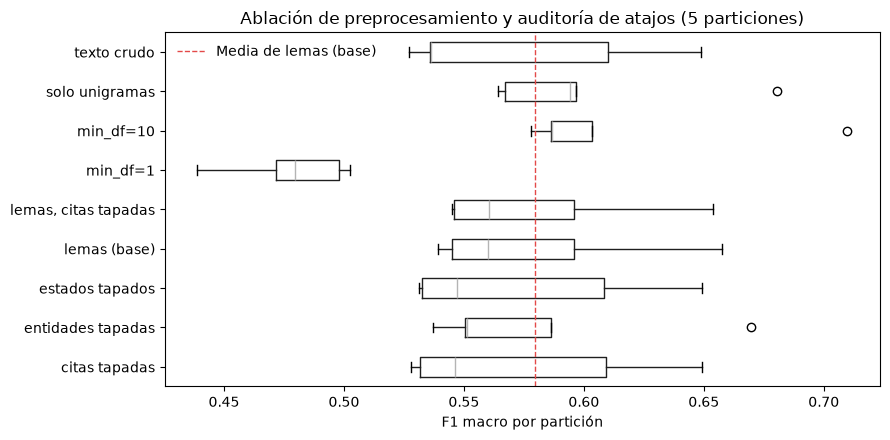

In [17]:
orden = tabla_ablacion.index.tolist()
ax = por_particion[orden].boxplot(vert=False, figsize=(9, 4.5), grid=False)
ax.axvline(por_particion["lemas (base)"].mean(), color=PALETA[7], linestyle="--", linewidth=1,
           label="Media de lemas (base)")
ax.set_xlabel("F1 macro por partición")
ax.set_title("Ablación de preprocesamiento y auditoría de atajos (5 particiones)")
ax.legend(frameon=False)
plt.tight_layout()
guardar_fig(ax.figure, "c05_t1_ablacion")
plt.show()

**Figura.** La variación entre particiones (de 0,05 a 0,10 de F1 macro) es mayor que casi todas las diferencias entre variantes. Solo `min_df=1` queda claramente por debajo en las 5 particiones, y `min_df=10` y los unigramas quedan algo por encima. Las variantes que tapan atajos se superponen con su referencia.

# 5. Ajustar hiperparámetros con validación anidada

In [18]:
from sklearn.model_selection import GridSearchCV
from iterstrat.ml_stratifiers import MultilabelStratifiedKFold

rejilla = {"onevsrestclassifier__estimator__C": [0.01, 0.03, 0.1, 0.3, 1, 10]}
filas, elegidos = [], []
for k, ent, pru in iterar_particiones(df):
    interna = MultilabelStratifiedKFold(n_splits=3, shuffle=True, random_state=SEMILLA)
    busqueda = GridSearchCV(tfidf_lr(), rejilla, scoring="f1_macro", cv=interna, n_jobs=-1)
    busqueda.fit(X[ent], Y[ent])                    # solo el entrenamiento de esta partición
    elegidos.append(busqueda.best_params_)
    P = busqueda.predict_proba(X[pru])
    filas.append({"modelo": "tfidf_lr_ajustado", "particion": k,
                  **metricas_multietiqueta(Y[pru], (P >= 0.5).astype(int), P)})
print(elegidos)
resumir(filas)

[{'onevsrestclassifier__estimator__C': 0.03}, {'onevsrestclassifier__estimator__C': 0.03}, {'onevsrestclassifier__estimator__C': 0.03}, {'onevsrestclassifier__estimator__C': 0.03}, {'onevsrestclassifier__estimator__C': 0.03}]


f1_micro       f1_macro         precision_micro         \
                      mean   std     mean     std            mean    std   
modelo                                                                     
tfidf_lr_ajustado   0.7478  0.04   0.5917  0.0493            0.75  0.054   

                  exhaustividad_micro         hamming          \
                                 mean     std    mean     std   
modelo                                                          
tfidf_lr_ajustado              0.7463  0.0324  0.1635  0.0237   

                  exactitud_estricta         ap_macro         ap_micro          
                                mean     std     mean     std     mean     std  
modelo                                                                          
tfidf_lr_ajustado             0.1129  0.0548   0.6685  0.0578   0.8351  0.0389

**Validación anidada, eligiendo C por F1 macro con umbral 0,5.** Gana C = 0,03 en las 5 particiones, y el F1 macro sube de 0,58 a 0,59.

Es una regularización muy fuerte: aplana las probabilidades hacia 0,5, y así más artículos raros cruzan el umbral (la exhaustividad sube de 0,73 a 0,75). En la práctica, elegir C por F1 con umbral fijo está ajustando el umbral de forma indirecta. Por eso el modelo final elige los hiperparámetros por AP, que no depende del umbral, y ajusta el umbral aparte (secciones 6 y 10).

# 6. Un umbral para cada artículo

In [19]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import f1_score


def umbrales_por_articulo(crear_modelo, X_ent, Y_ent):
    interna = MultilabelStratifiedKFold(n_splits=3, shuffle=True, random_state=SEMILLA)
    P = cross_val_predict(crear_modelo(), X_ent, Y_ent, cv=interna, method="predict_proba")
    candidatos = np.arange(0.05, 0.96, 0.05)
    return np.array([candidatos[np.argmax([f1_score(Y_ent[:, j], P[:, j] >= u, zero_division=0)
                                           for u in candidatos])]
                     for j in range(Y_ent.shape[1])])


filas, umbrales = [], []
for k, ent, pru in iterar_particiones(df):
    u = umbrales_por_articulo(tfidf_lr, X[ent], Y[ent])
    umbrales.append(u)
    P = tfidf_lr().fit(X[ent], Y[ent]).predict_proba(X[pru])
    filas.append({"modelo": "tfidf_lr_umbrales", "particion": k,
                  **metricas_multietiqueta(Y[pru], (P >= u).astype(int), P)})
display(resumir(filas))

# Umbral elegido para cada artículo en cada partición
pd.DataFrame(np.array(umbrales).T, index=pd.Index(etiquetas, name="articulo"),
             columns=[f"particion_{k}" for k in range(N_PARTICIONES)]).round(2)

f1_micro         f1_macro        precision_micro          \
                      mean     std     mean    std            mean     std   
modelo                                                                       
tfidf_lr_umbrales   0.7432  0.0359   0.6192  0.047          0.6742  0.0422   

                  exhaustividad_micro         hamming          \
                                 mean     std    mean     std   
modelo                                                          
tfidf_lr_umbrales              0.8285  0.0284   0.186  0.0241   

                  exactitud_estricta        ap_macro        ap_micro          
                                mean    std     mean    std     mean     std  
modelo                                                                        
tfidf_lr_umbrales             0.0648  0.028   0.6828  0.055   0.8502  0.0348

,particion_0,particion_1,particion_2,particion_3,particion_4
articulo,,,,,
3,0.45,0.50,0.50,0.50,0.45
4,0.50,0.50,0.50,0.45,0.45
5,0.50,0.50,0.50,0.50,0.50
7,0.50,0.45,0.45,0.45,0.50
8,0.05,0.05,0.05,0.05,0.05
11,0.45,0.45,0.45,0.45,0.45
13,0.45,0.45,0.40,0.45,0.45
17,0.45,0.50,0.45,0.50,0.45
19,0.45,0.45,0.45,0.45,0.45


**Un umbral por artículo** (elegido con predicciones fuera de partición del entrenamiento; modelo sin ajustar):

- **F1 macro:** sube de 0,58 a 0,62 sin tocar el modelo. La AP no cambia (0,68), porque las probabilidades son las mismas: solo cambia la regla para decidir cuándo marcar 1.
- **Exhaustividad micro:** sube de 0,73 a 0,83, y el modelo deja escapar pocas violaciones reales.
- **Precisión micro:** baja de 0,79 a 0,67. Con más etiquetas marcadas por sentencia, la exactitud estricta cae del 15 % al 6 %. Como herramienta, se parece más a un asistente que sugiere artículos para revisar que a un juez.

Los umbrales elegidos son estables entre particiones. Los artículos raros (23, 24, 26) bajan a 0,40, y el 8 baja hasta 0,05 porque casi siempre está presente. Marcarlo siempre cuesta poco.

# 7. Otros modelos

In [20]:
from sklearn.naive_bayes import ComplementNB
from sklearn.svm import LinearSVC

tfidf = lambda: TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_df=0.9, sublinear_tf=True)
filas = (evaluar("tfidf_nb", lambda: make_pipeline(tfidf(), OneVsRestClassifier(ComplementNB())), X)
       + evaluar("tfidf_svm", lambda: make_pipeline(tfidf(), OneVsRestClassifier(LinearSVC(class_weight="balanced", random_state=SEMILLA))), X))
resumir(filas)

f1_micro         f1_macro         precision_micro          \
              mean     std     mean     std            mean     std   
modelo                                                                
tfidf_nb    0.6944  0.0108   0.2725  0.0061          0.8231  0.0343   
tfidf_svm   0.7681  0.0236   0.5286  0.0339          0.8439  0.0431   

          exhaustividad_micro         hamming         exactitud_estricta  \
                         mean     std    mean     std               mean   
modelo                                                                     
tfidf_nb               0.6013  0.0156  0.1721  0.0067             0.0925   
tfidf_svm              0.7054  0.0210  0.1384  0.0118             0.1951   

                  ap_macro         ap_micro          
              std     mean     std     mean     std  
modelo                                               
tfidf_nb   0.0459   0.5174  0.0436   0.7752  0.0305  
tfidf_svm  0.0610   0.7044  0.0518   0.8623  0.0294

**Otros modelos con TF-IDF** (sin ajustar, umbral por defecto):

- **ComplementNB:** se queda en F1 macro 0,27, casi la línea base. Predice bien los artículos frecuentes y casi nunca los raros.
- **SVM lineal:** tiene la mejor AP de todo el recorrido (0,70) y la mejor exactitud estricta (20 %). Su F1 macro (0,53) es peor que el de la regresión logística: el corte por defecto (distancia 0) es conservador con los artículos raros. Necesita sus propios umbrales, y en la sección 10 los tiene.

In [21]:
from sentence_transformers import SentenceTransformer
import torch
dispositivo = "cuda" if torch.cuda.is_available() else "cpu"   # sin GPU usa la CPU (más lento)
print("Calculando embeddings en:", dispositivo)
e5 = SentenceTransformer("intfloat/multilingual-e5-base", device=dispositivo)
e5.max_seq_length = 512

def trozos(texto, n=250):
    palabras = texto.split()
    return [" ".join(palabras[i:i + n]) for i in range(0, len(palabras), n)]

pedazos = [(i, t) for i, txt in enumerate(df["texto"].map(tapar_citas)) for t in trozos(txt)]
V = e5.encode([f"passage: {t}" for _, t in pedazos], batch_size=64, normalize_embeddings=True)
duenio = np.array([i for i, _ in pedazos])                 # a qué sentencia pertenece cada trozo
E = np.zeros((len(df), V.shape[1]))
np.add.at(E, duenio, V)                                     # suma los vectores de cada sentencia
E /= np.bincount(duenio)[:, None]                           # y divide por el número de trozos
np.save(DIR_DATOS / "t1_embeddings_hechos.npy", E)

filas = evaluar("e5_lr", lambda: OneVsRestClassifier(
    LogisticRegression(class_weight="balanced", max_iter=2000)), E)
resumir(filas)

W1115 21:47:17.219000 29164 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Calculando embeddings en: cuda


f1_micro         f1_macro         precision_micro          \
           mean     std     mean     std            mean     std   
modelo                                                             
e5_lr    0.6773  0.0366   0.5818  0.0414          0.6112  0.0326   

       exhaustividad_micro         hamming         exactitud_estricta          \
                      mean     std    mean     std               mean     std   
modelo                                                                          
e5_lr               0.7598  0.0452  0.2349  0.0218             0.0329  0.0267   

       ap_macro         ap_micro          
           mean     std     mean     std  
modelo                                    
e5_lr    0.6476  0.0546   0.7569  0.0431

**Embeddings e5** (`multilingual-e5-base`). Los hechos se parten en trozos de 250 palabras, con las citas tapadas, y se promedian los vectores de los trozos.

Con regresión logística y umbral 0,5 da F1 macro 0,58 (igual que TF-IDF) y AP 0,65 (peor que TF-IDF). Marca muchas etiquetas: exhaustividad 0,76 y precisión 0,61. El modelo no se ajustó a este corpus, y el promedio de muchos trozos diluye la señal de los pasajes concretos. Aun así, sin vocabulario ni ajuste, queda cerca de TF-IDF.

# 8. Prueba temporal (modelo sin ajustar, umbral 0,5)

In [22]:
ent, pru = particion_temporal(df)
modelo = tfidf_lr().fit(X[ent], Y[ent])
P = modelo.predict_proba(X[pru])
print(metricas_multietiqueta(Y[pru], (P >= 0.5).astype(int), P))
f1_por_etiqueta(Y[pru], (P >= 0.5).astype(int), etiquetas)

{'f1_micro': 0.7140804597701149, 'f1_macro': 0.4475604740886727, 'precision_micro': 0.8628472222222222, 'exhaustividad_micro': 0.6090686274509803, 'hamming': 0.1679324894514768, 'exactitud_estricta': 0.14556962025316456, 'ap_macro': 0.6584319376053132, 'ap_micro': 0.8096492807255262}


,articulo,positivos,f1
0,3,26,0.540541
1,4,69,0.803279
2,5,104,0.880000
3,7,65,0.742424
4,8,150,0.967320
5,11,31,0.256410
6,13,48,0.040816
7,17,31,0.216216
8,19,38,0.177778
9,21,14,0.583333


**Prueba temporal con umbral 0,5** (entrenar con 147 sentencias hasta 2018 y evaluar con 158 desde 2019):

- **F1 macro:** cae a 0,45.
- **AP macro:** se mantiene en 0,66.

El modelo sigue ordenando bien las sentencias, pero el umbral fijo de 0,5 falla con la nueva distribución de etiquetas. El núcleo clásico (8, 25, 5, 4, 7) tiene un F1 de 0,74 o más. En cambio, se hunden los artículos que se volvieron frecuentes después de 2018: el 26 (0,09), el 13 (0,04) y el 24 (0,00). La sección 11 repite la prueba con el modelo final, para separar lo que se debe al umbral de lo que se debe al cambio en el tiempo.

# 9. ¿Es significativa la diferencia entre lemas y texto crudo?

In [23]:
def fuera_de_particion(crear_modelo, X):
    P = np.zeros(Y.shape)
    for k, ent, pru in iterar_particiones(df):
        P[pru] = crear_modelo().fit(X[ent], Y[ent]).predict_proba(X[pru])
    return P

def bootstrap_diferencia(P_a, P_b, umbral=0.5, n=1000):
    """Media e intervalo del 95 % de (F1 macro de A) − (F1 macro de B)."""
    rng = np.random.default_rng(SEMILLA)
    d = []
    for _ in range(n):
        i = rng.integers(0, len(Y), len(Y))       # las mismas sentencias para los dos modelos
        d.append(f1_score(Y[i], P_a[i] >= umbral, average="macro", zero_division=0)
                 - f1_score(Y[i], P_b[i] >= umbral, average="macro", zero_division=0))
    return np.mean(d), np.percentile(d, [2.5, 97.5])

P_lemas = fuera_de_particion(tfidf_lr, X)
P_texto = fuera_de_particion(tfidf_lr, df["texto"].to_numpy())
bootstrap_diferencia(P_lemas, P_texto)

(np.float64(0.006765630645241353), array([-0.00639988,  0.02026436]))

**Bootstrap pareado** (1000 remuestreos de las 305 predicciones fuera de partición, umbral 0,5). Diferencia de F1 macro entre lemas y texto crudo: +0,007, con intervalo del 95 % [−0,006; +0,020].

El intervalo incluye el 0: no se puede afirmar que lematizar mejore. Se mantienen los lemas por razones prácticas, no estadísticas: el vocabulario es más pequeño, se agrupan las flexiones del español, y en ninguna prueba los lemas quedaron peor.

# 10. Modelo final

Las secciones anteriores cambiaron una cosa a la vez. Aquí se juntan las mejoras en un único protocolo, que se aplica igual a los tres candidatos (TF-IDF + regresión logística, TF-IDF + SVM lineal y e5 + regresión logística). En cada una de las 5 particiones externas:

1. **Hiperparámetros.** `GridSearchCV`, con 3 particiones internas del entrenamiento, elige el vocabulario (`min_df`, n-gramas) y la regularización (C). Se elige por **AP macro**, que no depende del umbral: así no se repite lo de la sección 5, donde elegir por F1 con umbral fijo terminaba ajustando el umbral por la vía de C.
2. **Umbrales.** Con esos hiperparámetros, `cross_val_predict` en las mismas particiones internas da puntajes fuera de partición del entrenamiento. Con ellos se elige un umbral por artículo: el que maximiza su F1 entre 19 cuantiles de los puntajes. Los cuantiles sirven igual para las probabilidades de la regresión logística y para la distancia al hiperplano del SVM.
3. **Evaluación.** Se mide una sola vez en la partición externa de prueba.

**Entrada.** Lemas con las citas de artículos tapadas (sección 4). Para e5, los embeddings de la sección 7. La rejilla de C de la regresión logística llega hasta 1000, porque con umbrales propios el modelo tolera menos regularización.

In [24]:
from collections import Counter
from sklearn.base import clone
from sklearn.metrics import average_precision_score, precision_score, recall_score


def puntajes(modelo, X):
    """Probabilidades si el modelo las da; si no (SVM), la distancia al hiperplano."""
    return modelo.predict_proba(X) if hasattr(modelo, "predict_proba") else modelo.decision_function(X)


def elegir_umbrales(P, Y_ent):
    """Para cada artículo, el cuantil de sus puntajes (del 5 % al 95 %) que maximiza su F1."""
    u = []
    for j in range(Y_ent.shape[1]):
        cand = np.quantile(P[:, j], np.linspace(0.05, 0.95, 19))
        u.append(cand[np.argmax([f1_score(Y_ent[:, j], P[:, j] >= c, zero_division=0) for c in cand])])
    return np.array(u)


def ajustar(base, rejilla, X_ent, Y_ent):
    """Elige hiperparámetros (por AP macro) y umbrales usando solo el entrenamiento."""
    interna = MultilabelStratifiedKFold(n_splits=3, shuffle=True, random_state=SEMILLA)
    busqueda = GridSearchCV(base, rejilla, scoring="average_precision", cv=interna, n_jobs=-1).fit(X_ent, Y_ent)
    mejor = clone(base).set_params(**busqueda.best_params_)
    metodo = "predict_proba" if hasattr(mejor, "predict_proba") else "decision_function"
    P_int = cross_val_predict(mejor, X_ent, Y_ent, cv=interna, method=metodo)   # puntajes fuera de partición internos
    return busqueda.best_estimator_, elegir_umbrales(P_int, Y_ent), busqueda.best_params_


def validar(nombre, base, rejilla, X):
    """Validación anidada en las 5 particiones: métricas por partición y predicciones fuera de partición."""
    filas, B, P_oof, params, umbrales = [], np.zeros(Y.shape, int), np.zeros(Y.shape), [], []
    for k, ent, pru in iterar_particiones(df):
        modelo, u, p = ajustar(base, rejilla, X[ent], Y[ent])
        P = puntajes(modelo, X[pru])
        B[pru], P_oof[pru] = (P >= u).astype(int), P
        params.append(p)
        umbrales.append(u)
        filas.append({"modelo": nombre, "particion": k, **metricas_multietiqueta(Y[pru], B[pru], P)})
    return {"filas": filas, "B": B, "P": P_oof, "params": params, "umbrales": np.array(umbrales)}

In [25]:
from sklearn.svm import LinearSVC

base_lr = make_pipeline(TfidfVectorizer(max_df=0.9, sublinear_tf=True),
                        OneVsRestClassifier(LogisticRegression(class_weight="balanced", max_iter=2000)))
rejilla_lr = {"tfidfvectorizer__min_df": [3, 10, 20, 40],
              "tfidfvectorizer__ngram_range": [(1, 1), (1, 2)],
              "onevsrestclassifier__estimator__C": [0.1, 1, 10, 30, 100, 300, 1000]}
base_svm = make_pipeline(TfidfVectorizer(max_df=0.9, sublinear_tf=True),
                         OneVsRestClassifier(LinearSVC(class_weight="balanced", random_state=SEMILLA)))
rejilla_svm = {**rejilla_lr, "onevsrestclassifier__estimator__C": [0.01, 0.1, 1, 10]}
base_e5 = OneVsRestClassifier(LogisticRegression(class_weight="balanced", max_iter=5000))
rejilla_e5 = {"estimator__C": [1, 10, 100, 1000, 10000]}

# Entrada del modelo final: lemas con las citas de artículos tapadas (sección 4: no cambia el rendimiento,
# y así ningún resultado depende de que el texto de los hechos nombre el artículo)
X_final = df["lemas"].map(tapar_citas).to_numpy()

R = {nombre: validar(nombre, base, rejilla, Xv) for nombre, base, rejilla, Xv in [
    ("tfidf_lr_final", base_lr, rejilla_lr, X_final),
    ("tfidf_svm_final", base_svm, rejilla_svm, X_final),
    ("e5_lr_final", base_e5, rejilla_e5, E)]}

# Junto a las referencias: la línea base (sección 2) y TF-IDF + LR sin ajustar con umbral 0,5 (sección 3)
tabla_modelos = resumir(filas_base + resultados + sum((r["filas"] for r in R.values()), []))
guardar_tabla(tabla_modelos, "t1_modelos")
tabla_modelos[["f1_macro", "ap_macro", "f1_micro", "precision_micro", "exhaustividad_micro", "hamming",
               "exactitud_estricta"]]

f1_macro         ap_macro         f1_micro          \
                    mean     std     mean     std     mean     std   
modelo                                                               
e5_lr_final       0.6031  0.0407   0.6742  0.0484   0.7245  0.0307   
linea_base        0.1773  0.0036   0.3254  0.0138   0.6112  0.0087   
tfidf_lr          0.5796  0.0488   0.6828  0.0550   0.7582  0.0385   
tfidf_lr_final    0.6249  0.0613   0.6906  0.0467   0.7422  0.0391   
tfidf_svm_final   0.6345  0.0587   0.6971  0.0569   0.7432  0.0456   

                precision_micro         exhaustividad_micro         hamming  \
                           mean     std                mean     std    mean   
modelo                                                                        
e5_lr_final              0.6650  0.0326              0.7987  0.0612  0.1967   
linea_base               0.8030  0.0293              0.4936  0.0067  0.2042   
tfidf_lr                 0.7862  0.0536              0.7329  0.0325  0.1517   
tfidf_lr_final           0.6851  0.0487              0.8123  0.0481  0.1829   
tfidf_svm_final          0.6942  0.0567              0.8015  0.0445  0.1797   

                        exactitud_estricta          
                    std               mean     std  
modelo                                              
e5_lr_final      0.0153             0.0748  0.0297  
linea_base       0.0045             0.0235  0.0224  
tfidf_lr         0.0215             0.1527  0.0754  
tfidf_lr_final   0.0240             0.1012  0.0306  
tfidf_svm_final  0.0291             0.0982  0.0244

In [26]:
# Hiperparámetros elegidos en cada partición externa
tabla_parametros = pd.DataFrame([{"modelo": n, "particion": k, **{c.split("__")[-1]: v for c, v in p.items()}}
                                 for n, r in R.items() for k, p in enumerate(r["params"])])
guardar_tabla(tabla_parametros.set_index(["modelo", "particion"]), "t1_parametros")
tabla_parametros

,modelo,particion,C,min_df,ngram_range
0,tfidf_lr_final,0,10,20.0,"(1, 2)"
1,tfidf_lr_final,1,100,10.0,"(1, 2)"
2,tfidf_lr_final,2,300,3.0,"(1, 2)"
3,tfidf_lr_final,3,100,3.0,"(1, 1)"
4,tfidf_lr_final,4,30,20.0,"(1, 1)"
5,tfidf_svm_final,0,10,3.0,"(1, 1)"
6,tfidf_svm_final,1,10,3.0,"(1, 2)"
7,tfidf_svm_final,2,10,3.0,"(1, 2)"
8,tfidf_svm_final,3,10,3.0,"(1, 1)"
9,tfidf_svm_final,4,1,20.0,"(1, 1)"


In [27]:
def bootstrap_dif(B_a, B_b, n=1000):
    """Media e intervalo del 95 % de F1 macro(A) − F1 macro(B), remuestreando las mismas sentencias para los dos."""
    rng = np.random.default_rng(SEMILLA)
    d = [f1_score(Y[i], B_a[i], average="macro", zero_division=0) - f1_score(Y[i], B_b[i], average="macro", zero_division=0)
         for i in (rng.integers(0, len(Y), len(Y)) for _ in range(n))]
    return np.mean(d), *np.percentile(d, [2.5, 97.5])


B_base = np.zeros(Y.shape, int)
for k, ent, pru in iterar_particiones(df):
    B_base[pru] = Y[ent].mean(axis=0) >= 0.5
B_final, P_final = R["tfidf_lr_final"]["B"], R["tfidf_lr_final"]["P"]
pares = {"tfidf_lr_final − línea base": (B_final, B_base),
         "tfidf_lr_final − tfidf_lr (umbral 0,5)": (B_final, (P_lemas >= 0.5).astype(int)),
         "tfidf_lr_final − tfidf_svm_final": (B_final, R["tfidf_svm_final"]["B"]),
         "tfidf_lr_final − e5_lr_final": (B_final, R["e5_lr_final"]["B"]),
         "tfidf_svm_final − e5_lr_final": (R["tfidf_svm_final"]["B"], R["e5_lr_final"]["B"])}
tabla_comparaciones = pd.DataFrame([bootstrap_dif(a, b) for a, b in pares.values()], index=list(pares),
                                   columns=["diferencia_f1_macro", "ic95_inf", "ic95_sup"]).round(4)
guardar_tabla(tabla_comparaciones, "t1_comparaciones")
tabla_comparaciones

,diferencia_f1_macro,ic95_inf,ic95_sup
tfidf_lr_final − línea base,0.4498,0.4241,0.4763
"tfidf_lr_final − tfidf_lr (umbral 0,5)",0.0456,0.0177,0.0780
tfidf_lr_final − tfidf_svm_final,-0.0051,-0.0188,0.0091
tfidf_lr_final − e5_lr_final,0.0224,-0.0000,0.0446
tfidf_svm_final − e5_lr_final,0.0274,0.0058,0.0486


**Resultados del modelo final** (media de las 5 particiones externas):

| Modelo | F1 macro | AP macro | F1 micro | Exactitud estricta |
|---|---|---|---|---|
| Línea base | 0,18 | 0,33 | 0,61 | 0,02 |
| TF-IDF + LR, sin ajustar (umbral 0,5) | 0,58 | 0,68 | 0,76 | 0,15 |
| **TF-IDF + LR, final** | **0,62** ± 0,06 | 0,69 | 0,74 | 0,10 |
| TF-IDF + SVM, final | 0,63 ± 0,06 | 0,70 | 0,74 | 0,10 |
| e5 + LR, final | 0,60 ± 0,04 | 0,67 | 0,72 | 0,07 |

**Comparaciones** (bootstrap pareado sobre las predicciones fuera de partición; diferencia de F1 macro e intervalo del 95 %):

- **Frente a la línea base:** +0,45 [0,42; 0,48].
- **Frente al mismo modelo sin ajustar:** +0,046 [0,018; 0,078]. Elegir hiperparámetros por AP y fijar un umbral por artículo mejora de forma significativa, a cambio de precisión y exactitud estricta.
- **TF-IDF + LR frente a TF-IDF + SVM:** −0,005 [−0,019; +0,009]. Es un empate.
- **TF-IDF frente a e5:** +0,022 [0,000; +0,045] con regresión logística, en el límite, y +0,027 [0,006; 0,049] con SVM. La representación TF-IDF aprovecha mejor el vocabulario jurídico específico que un modelo general de embeddings sin ajustar.

**Hiperparámetros.** Varían bastante entre particiones: C entre 10 y 300, `min_df` entre 3 y 20, con y sin bigramas. La superficie de AP es plana: muchas configuraciones rinden casi igual, y la diferencia la hace el umbral, no la configuración exacta.

**Modelo elegido: TF-IDF + regresión logística.** Empata con el SVM y da probabilidades, que se pueden leer y que sirven para la prueba temporal y para interpretar.

# 11. Prueba temporal con el modelo final

In [28]:
ent, pru = particion_temporal(df)
modelo_t, u_t, p_t = ajustar(base_lr, rejilla_lr, X_final[ent], Y[ent])     # todo se elige con las sentencias hasta 2018
P_t = modelo_t.predict_proba(X_final[pru])
P_t05 = tfidf_lr().fit(X[ent], Y[ent]).predict_proba(X[pru])          # el modelo de la sección 8
print("Hiperparámetros elegidos con las sentencias hasta 2018:", p_t)

tabla_temporal = pd.DataFrame({
    "positivos_hasta_2018": Y[ent].sum(0), "positivos_desde_2019": Y[pru].sum(0),
    # las mismas sentencias recientes, pero predichas por la validación cruzada (entrenada con años mezclados)
    "cv_mismas_sentencias": f1_score(Y[pru], B_final[pru], average=None, zero_division=0),
    "temporal_umbral_05": f1_score(Y[pru], P_t05 >= 0.5, average=None, zero_division=0),
    "temporal_final": f1_score(Y[pru], P_t >= u_t, average=None, zero_division=0)},
    index=pd.Index(etiquetas, name="articulo")).round(3)
guardar_tabla(tabla_temporal, "t1_temporal")

resumen_temporal = pd.DataFrame({
    "f1_macro": tabla_temporal.iloc[:, 2:].mean(),
    "ap_macro": [average_precision_score(Y[pru], P_final[pru]), average_precision_score(Y[pru], P_t05),
                 average_precision_score(Y[pru], P_t)]}).round(3)
display(resumen_temporal)
tabla_temporal

Hiperparámetros elegidos con las sentencias hasta 2018: {'onevsrestclassifier__estimator__C': 300, 'tfidfvectorizer__min_df': 3, 'tfidfvectorizer__ngram_range': (1, 1)}


,f1_macro,ap_macro
cv_mismas_sentencias,0.665,0.674
temporal_umbral_05,0.448,0.658
temporal_final,0.623,0.670


,positivos_hasta_2018,positivos_desde_2019,cv_mismas_sentencias,temporal_umbral_05,temporal_final
articulo,,,,,
3,26,26,0.717,0.541,0.681
4,67,69,0.837,0.803,0.847
5,102,104,0.887,0.880,0.879
7,66,65,0.780,0.742,0.748
8,134,150,0.946,0.967,0.932
11,26,31,0.514,0.256,0.506
13,15,48,0.579,0.041,0.290
17,16,31,0.540,0.216,0.391
19,24,38,0.529,0.178,0.604


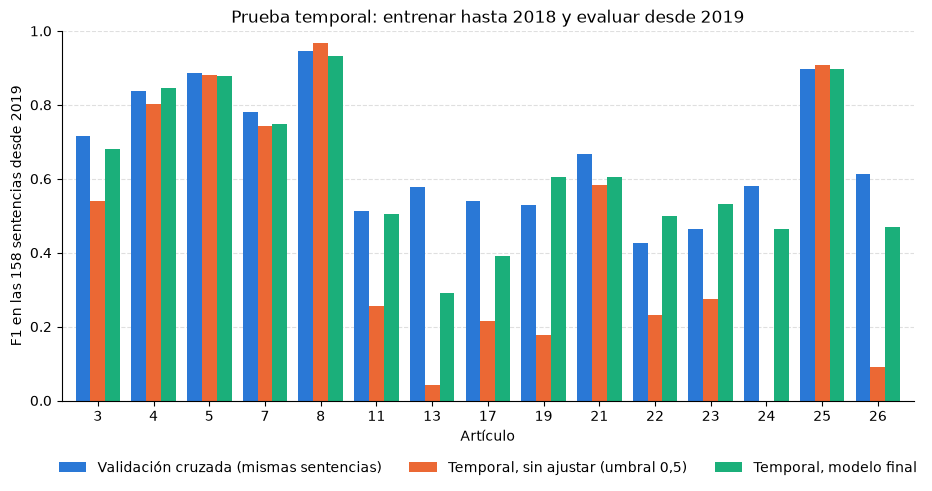

In [29]:
fig, ax = plt.subplots(figsize=(11, 4.8))
tabla_temporal[["cv_mismas_sentencias", "temporal_umbral_05", "temporal_final"]].plot.bar(
    ax=ax, color=PALETA[:3], width=0.8, rot=0)
ax.set(xlabel="Artículo", ylabel=f"F1 en las {len(pru)} sentencias desde 2019", ylim=(0, 1),
       title="Prueba temporal: entrenar hasta 2018 y evaluar desde 2019")
ax.legend(["Validación cruzada (mismas sentencias)", "Temporal, sin ajustar (umbral 0,5)", "Temporal, modelo final"],
          frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.13))
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)
guardar_fig(fig, "c04_t1_temporal")
plt.show()

**Prueba temporal con el modelo final** (todo se elige con las sentencias hasta 2018, y se evalúa una sola vez con las 158 desde 2019):

| | F1 macro | AP macro |
|---|---|---|
| Validación cruzada, mismas 158 sentencias | 0,665 | 0,674 |
| Temporal sin ajustar (umbral 0,5) | 0,448 | 0,658 |
| Temporal, modelo final | **0,623** | 0,670 |

- **La mayor parte del colapso temporal era el umbral.** Con umbrales por artículo, el F1 macro temporal sube de 0,45 a 0,62. Queda a 0,04 de la validación cruzada sobre las mismas sentencias. La AP casi no cambia en ninguna de las tres: el modelo histórico ordena las sentencias nuevas casi tan bien como uno que vio todas las épocas.
- **Lo que sí pierde el tiempo.** Los artículos 13 (0,58 en validación cruzada frente a 0,29 en temporal), 26 (0,61 frente a 0,47), 17 (0,54 frente a 0,39) y 24 (0,58 frente a 0,46). Son los de mayor desplazamiento de etiquetas, con entre 5 y 16 ejemplos hasta 2018.
- **Lo que no pierde.** El núcleo clásico queda igual. Sus diferencias son de ±0,04. El 19, el 22 y el 23 incluso mejoran en unos 0,07, pero con 18 a 38 positivos eso son pocas sentencias, y puede ser azar.

# 12. Resultados por artículo

In [30]:
tabla_articulos = pd.DataFrame({
    "positivos": Y.sum(0),
    "precision": precision_score(Y, B_final, average=None, zero_division=0),
    "exhaustividad": recall_score(Y, B_final, average=None, zero_division=0),
    "f1": f1_score(Y, B_final, average=None, zero_division=0),
    "ap": average_precision_score(Y, P_final, average=None),
    "umbral_medio": R["tfidf_lr_final"]["umbrales"].mean(0)}, index=pd.Index(etiquetas, name="articulo")).round(3)
guardar_tabla(tabla_articulos, "t1_por_articulo")
print("Correlación de Spearman entre F1 y número de positivos:",
      round(tabla_articulos["f1"].corr(tabla_articulos["positivos"], method="spearman"), 2))
tabla_articulos.sort_values("f1")

Correlación de Spearman entre F1 y número de positivos: 0.72


,positivos,precision,exhaustividad,f1,ap,umbral_medio
articulo,,,,,,
22,41,0.354,0.561,0.434,0.364,0.169
23,35,0.364,0.571,0.444,0.537,0.270
11,57,0.382,0.596,0.466,0.434,0.218
13,63,0.376,0.651,0.477,0.462,0.180
19,62,0.368,0.742,0.492,0.457,0.165
24,43,0.489,0.512,0.500,0.485,0.220
26,47,0.420,0.617,0.500,0.453,0.225
17,47,0.469,0.638,0.541,0.511,0.245
21,39,0.647,0.564,0.603,0.587,0.253


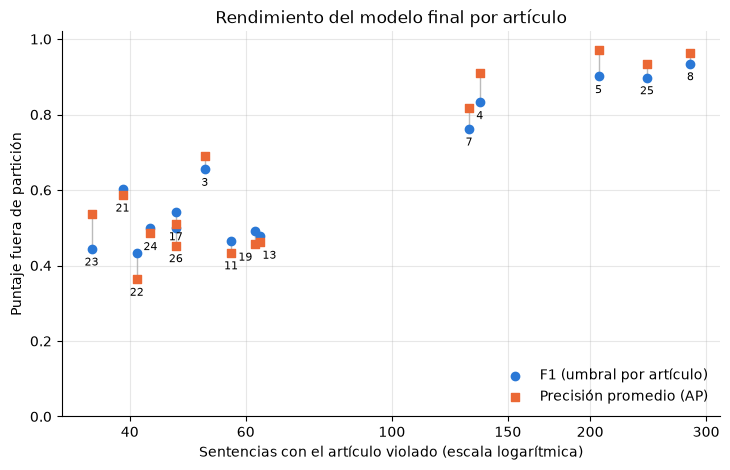

In [31]:
fig, ax = plt.subplots(figsize=(8.5, 5))
t = tabla_articulos
ax.vlines(t["positivos"], t[["f1", "ap"]].min(axis=1), t[["f1", "ap"]].max(axis=1), color="#bbbbbb", lw=1, zorder=1)
ax.scatter(t["positivos"], t["f1"], color=PALETA[0], label="F1 (umbral por artículo)", zorder=3)
ax.scatter(t["positivos"], t["ap"], color=PALETA[1], marker="s", label="Precisión promedio (AP)", zorder=3)
desplazar = {13: 7, 19: -7}            # 13 y 19 tienen casi el mismo número de positivos
for a, fila in t.iterrows():
    ax.annotate(str(a), (fila["positivos"], min(fila["f1"], fila["ap"])), textcoords="offset points",
                xytext=(desplazar.get(a, 0), -12), ha="center", fontsize=8)
ax.set_xscale("log")
ax.set_xticks([40, 60, 100, 150, 200, 300], labels=["40", "60", "100", "150", "200", "300"])
ax.minorticks_off()
ax.set( ylim=(0, 1.02), xlabel="Sentencias con el artículo violado (escala logarítmica)",
       ylabel="Puntaje fuera de partición", title="Rendimiento del modelo final por artículo")
ax.legend(frameon=False, loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(alpha=0.3)
guardar_fig(fig, "c03_t1_por_articulo")
plt.show()

**Por artículo** (predicciones fuera de partición del modelo final):

- **Muy bien** (F1 0,83–0,94): los artículos frecuentes 8, 5, 25 y 4.
- **Bien** (F1 0,60–0,76): el 7, el 3 y el 21. Los dos últimos tienen pocos ejemplos (52 y 39), pero un vocabulario muy propio: *desaparición, paradero* para el 3; *territorio, comunidad, tierra* para el 21.
- **Regular** (F1 0,43–0,54): los otros 8 artículos. Su precisión va de 0,35 a 0,49 y su exhaustividad de 0,51 a 0,74. El modelo encuentra la mayoría de los positivos, pero con uno o dos falsos positivos por acierto.

**Relación con el número de ejemplos.** La correlación de Spearman entre el F1 y el número de positivos es de 0,72: el número de ejemplos explica buena parte de la diferencia. El vocabulario también cuenta. El 21 (39 positivos) supera al 13 (63) y al 19 (62), cuyos hechos se parecen a los de otros artículos: el 13 a los de desaparición, el 19 a los de familia.

# 13. Interpretar y analizar errores

In [32]:
# La configuración más elegida por la validación anidada, entrenada con todos los datos:
# solo para interpretar, no para medir
moda = dict(Counter(tuple(sorted(p.items())) for p in R["tfidf_lr_final"]["params"]).most_common(1)[0][0])
print("Configuración:", moda)
modelo = clone(base_lr).set_params(**moda).fit(X_final, Y)
vocabulario = modelo[0].get_feature_names_out()
for j, a in enumerate(etiquetas):
    pesos = modelo[-1].estimators_[j].coef_[0]
    print(f"{a:>2}:", ", ".join(vocabulario[np.argsort(pesos)[-10:][::-1]]))

Configuración: {'onevsrestclassifier__estimator__C': 10, 'tfidfvectorizer__min_df': 20, 'tfidfvectorizer__ngram_range': (1, 2)}


 3: desaparición, desaparición forzado, paradero, forzado, desaparecido, búsqueda, universidad, reyes, destino, hijo
 4: muerte, desaparición, asesinato, cadáver, desaparición forzado, forzado, disparo, fallecer, pedro, santa
 5: médico, celda, tratamiento, corpus, detenido, niña, familiar, muerte, familia, paciente
 7: detención, san, detenido, prisión preventivo, desaparición, paradero, libertad, libertad señor, preventivo, identidad
 8: fiscal, auto, sociedad, constar, ejército, reparación, queja, homicidio, presidente, extraordinario
11: sexual, mujer, allanamiento, san, miguel, violencia sexual, violencia, sentir, discriminación, consentimiento
13: periodista, silva, expresión, libertad expresión, chile, difusión, calificación, seguimiento, prensa, rural
17: niña, familia, esposo, hija, silva, local, niño, esposa, departamental, paramilitar
19: niña, niño, adolescente, menor, familia, silva, colombia, departamental, costo, joven
21: territorio, tierra, comunidad, propiedad, área, 

**Términos con más peso** (configuración más elegida: C = 10, `min_df=20`, unigramas y bigramas, entrenada con todos los datos solo para interpretar):

- **Núcleos jurídicos reconocibles.** 3: *desaparición forzada, paradero, búsqueda*. 4: *muerte, asesinato, disparo*. 7: *detención, prisión preventiva*. 11: *violencia sexual, allanamiento*. 13: *periodista, libertad de expresión, prensa*. 21: *territorio, tierra, comunidad*. 23: *electoral, partido político, destitución*. 24: *discriminación, contra la mujer, igualdad, estructural*. 26: *laboral, trabajador, paciente, salud*.
- **Memorización de casos.** Entre los términos aparecen nombres propios: *silva* (13, 17, 19), *reyes* (3), *pedro* (4), *álvarez* (22), *san miguel* (11). Son nombres y apellidos que se repiten en al menos 20 sentencias (`min_df=20`), y el modelo los asocia con los artículos de los casos donde más pesan. Es poco, pero es señal de sobreajuste con tan pocos ejemplos.
- **Artículos casi siempre presentes.** El 8 y el 25 no tienen un vocabulario propio: sus pesos altos son términos procesales generales (*fiscal, auto, folio, anexo*).

In [33]:
import re

# Falsos negativos (FN: violado, el modelo dijo que no) y falsos positivos (FP) del modelo final, fuera de partición,
# en tres artículos difíciles. Se cuentan palabras clave del derecho en los hechos y se mira si los puntos
# resolutivos nombran el artículo (para revisar la etiqueta).
resolutivos = (pd.read_parquet(BASE_DIR / "procesado/parrafos.parquet", columns=["doc_id", "parte", "texto", "orden"])
               .query("parte == 'resolutivos'").sort_values("orden").groupby("doc_id")["texto"].apply(" ".join))
CLAVE = {13: r"expresi[óo]n|periodis|prensa|opini[óo]n|informaci[óo]n",
         24: r"discrimin|igualdad",
         26: r"salud|trabaj|laboral|pensi[óo]n|seguridad social|educaci[óo]n|ambient|agua|vivienda"}
filas_err = []
for a, patron in CLAVE.items():
    j = etiquetas.index(a)
    for tipo, m in [("FN", (Y[:, j] == 1) & (B_final[:, j] == 0)), ("FP", (Y[:, j] == 0) & (B_final[:, j] == 1))]:
        for i in np.flatnonzero(m):
            res = resolutivos.get(df.loc[i, "doc_id"], "")
            filas_err.append({
                "articulo": a, "error": tipo, "titulo": df.loc[i, "titulo"][:70], "anio": int(df.loc[i, "anio"]),
                "puntaje": round(P_final[i, j], 2),
                "umbral": round(R["tfidf_lr_final"]["umbrales"][df.loc[i, "particion"], j], 2),
                "palabras_clave": len(re.findall(patron, df.loc[i, "texto"], flags=re.I)),
                "resolutivos_lo_nombran": bool(re.search(rf"art[íi]culos?[^.]{{0,80}}\b{a}\b", res)),
                "etiquetas": list(df.loc[i, "articulos"])})
errores = pd.DataFrame(filas_err)
display(errores.groupby(["articulo", "error"]).size().unstack())

# Los errores más seguros de cada tipo: FN con el puntaje más bajo y FP con el más alto
errores["seguridad"] = np.where(errores["error"] == "FP", errores["puntaje"], -errores["puntaje"])
pd.set_option("display.max_colwidth", 70)
pd.set_option("display.width", 250)
(errores.sort_values("seguridad", ascending=False).groupby(["articulo", "error"]).head(5)
 .sort_values(["articulo", "error", "seguridad"], ascending=[True, True, False]).drop(columns="seguridad")
 .set_index(["articulo", "error"]))

error,FN,FP
articulo,,
13,22,68
24,21,23
26,18,40


titulo  anio  puntaje  umbral  palabras_clave  resolutivos_lo_nombran                                         etiquetas
articulo error                                                                                                                                                                                        
13       FN                                    caso núñez naranjo y otros vs. ecuador  2023     0.02    0.13               4                   False                           [3, 4, 5, 7, 8, 13, 25]
         FN                                     caso rojas riera y otra vs. venezuela  2026     0.03    0.12               7                    True                         [5, 7, 8, 13, 15, 23, 25]
         FN                                    caso deras garcía y otros vs. honduras  2022     0.04    0.24               2                   False  [4, 5, 7, 8, 11, 13, 16, 17, 19, 21, 22, 23, 25]
         FN     caso “la última tentación de cristo” (olmedo bustos y otros) vs. c...  2001     0.05    0.12               0                    True                                              [13]
         FN                                    caso pérez lucas y otros vs. guatemala  2024     0.06    0.13              12                   False           [3, 4, 5, 7, 8, 13, 16, 17, 19, 22, 25]
         FP                                    caso garzón guzmán y otros vs. ecuador  2021     0.90    0.13               7                   False                               [3, 4, 5, 7, 8, 25]
         FP                                caso movilla galarcio y otros vs. colombia  2022     0.78    0.12              18                   False                   [3, 4, 5, 7, 8, 16, 17, 19, 25]
         FP                             caso villaseñor velarde y otros vs. guatemala  2019     0.74    0.28              25                   False                                        [5, 8, 25]
         FP                       caso pueblo indígena kichwa de sarayaku vs. ecuador  2012     0.68    0.24              10                    True                                       [8, 21, 25]
         FP                                  caso ascencio rosario y otros vs. méxico  2025     0.66    0.13              43                    True                         [4, 5, 8, 11, 24, 25, 26]
24       FN                                                caso almeida vs. argentina  2020     0.01    0.29               0                   False                                       [8, 24, 25]
         FN     caso de las comunidades afrodescendientes desplazadas de la cuenca...  2013     0.02    0.20               3                    True             [4, 5, 8, 11, 17, 19, 21, 22, 24, 25]
         FN                                   caso garcía rodríguez y otro vs. méxico  2023     0.03    0.13               0                   False                                 [5, 7, 8, 24, 25]
         FN                      caso nadege dorzema y otros vs. república dominicana  2012     0.03    0.13               4                    True                       [3, 4, 5, 7, 8, 22, 24, 25]
         FN                                              caso flor freire vs. ecuador  2016     0.04    0.29               3                    True                                       [8, 11, 24]
         FP                                caso ramírez escobar y otros vs. guatemala  2018     0.62    0.38               0                   False                     [5, 7, 8, 11, 17, 18, 19, 25]
         FP                                    caso gonzales lluy y otros vs. ecuador  2015     0.59    0.29               2                   False                                     [4, 5, 8, 19]
         FP                                     caso azul rojas marín y otra vs. perú  2020     0.52    0.38               7                   False                                 [5, 7, 8, 11, 25]
         FP                                     caso beatriz1 y otros vs. el salvador  2024     0.4

**Lectura de errores en tres artículos difíciles.** Las tablas muestran los errores más seguros de cada tipo. Se leyeron los hechos y los puntos resolutivos.

**Art. 26 (DESCA): la etiqueta depende de la doctrina de la época (*concept drift*).**
- **Falsos positivos más seguros.** Son casos de salud o trabajo anteriores a 2017: *Chinchilla Sandoval* (2016, p = 0,92), *I.V. vs. Bolivia* (2016), *Gonzales Lluy* (2015) y *Trabajadores cesados del Congreso* (2006). Los hechos hablan de salud y trabajo (de 26 a 64 palabras clave), pero la Corte los resolvió con otros artículos (4, 5, 8, 25). Solo desde *Lagos del Campo* (2017) declara violado el 26 directamente.
- **Lectura.** El modelo no se equivoca sobre los hechos: la etiqueta cambió de criterio. Ningún clasificador de hechos puede acertar esos casos sin saber el año.
- **Falsos negativos.** Hay casos recientes en los que el 26 acompaña a hechos dominados por otra violación: *Zapata vs. Colombia* (2025, derecho al trabajo en un caso de violencia), *Gutiérrez Navas* (destitución de magistrados) y *Ascencio Rosario*.

**Art. 24 (igualdad): la discriminación es una calificación jurídica, no un hecho.**
- **Falsos negativos.** En *Almeida vs. Argentina* y *García Rodríguez vs. México* no hay ninguna palabra sobre discriminación o igualdad en los hechos. La Corte llega al 24 al comparar el trato con el de otras personas, en el fondo de la sentencia.
- **Falsos positivos.** *Ramírez Escobar*, *Azul Rojas Marín* y *Beatriz* hablan de discriminación, pero la Corte la declaró dentro de otros derechos, en relación con el artículo 1.1, y no como violación autónoma del 24.

**Art. 13 (expresión e información): dos derechos con la misma etiqueta.**
- **Falsos negativos.** El 13 aparece como derecho a la verdad o de acceso a la información en casos de desaparición (*Núñez Naranjo*, *Deras García*, *Pérez Lucas*). Los hechos casi no hablan de expresión, y el modelo los ve como casos de 3, 4, 5 y 7.
- **Falsos positivos.** El más seguro es *Garzón Guzmán* (p = 0,90), una desaparición de 1990 sin el 13 declarado: el modelo aprendió que las desapariciones recientes suelen llevar el 13, que es el cambio visto en la sección 1. Otros falsos positivos tienen hechos sobre prensa o información en los que la Corte no declaró el 13. *Ascencio Rosario* (p = 0,66) es el caso claro: los resolutivos dicen que «el Estado **no** es responsable por la violación del derecho de acceso a la información». La etiqueta es correcta, y el modelo no puede saber cómo resolvió la Corte.

**Errores en las propias etiquetas.** Al leer estos errores con las etiquetas anteriores apareció un fallo de la regla que las extrae: listas como «artículos 7.1, 11.2, y 26» perdían el último artículo (por ejemplo, *Pavez Pavez* sí tiene el 26). Se corrigió en `construir_conjuntos.py` y en el notebook de la Entrega 1, y cambiaron 10 etiquetas de este conjunto. El conteo de palabras clave también engaña: en *Agua Caliente* la palabra «agua» viene del nombre de la comunidad.

# 14. Conclusiones

1. **Los hechos bastan para predecir buena parte de los artículos violados.** El modelo final (TF-IDF de lemas, regresión logística, hiperparámetros elegidos por AP y un umbral por artículo, todo dentro de la validación anidada) llega a F1 macro 0,62 ± 0,06 y AP macro 0,69. La línea base sin texto se queda en 0,18 y 0,33. Los artículos frecuentes o con vocabulario propio (8, 5, 25, 4, 7, 3, 21) se predicen bien (F1 de 0,60 a 0,94). Los raros quedan entre 0,43 y 0,54.
2. **El umbral importa más que el modelo.** Fijar un umbral por artículo suma unos 0,04 de F1 macro, una diferencia significativa. En cambio, la regresión logística empata con el SVM. TF-IDF supera a e5 sin ajustar por unos 0,02 a 0,03, una diferencia en el límite de la significancia. Los hiperparámetros cambian entre particiones sin que cambie el rendimiento.
3. **Sin atajos detectables.** Tapar las citas de artículos (también las que la Entrega 1 dejó en los lemas como `art_N`), los Estados o las personas y lugares no baja el rendimiento. Para el modelo final se usan los lemas con las citas tapadas.
4. **El paso del tiempo se debe sobre todo al umbral.** Al entrenar hasta 2018, el F1 macro con umbral 0,5 cae a 0,45. Con el protocolo final queda en 0,62, cerca de los 0,665 de la validación cruzada sobre las mismas sentencias, y la AP apenas cambia. La pérdida real se concentra en los artículos que crecieron después de 2018 (13, 26, 17, 24).
5. **Parte del error está en la etiqueta, no en el modelo.**
   - **Doctrina que cambia con el tiempo.** El artículo 26 cambia de criterio con el tiempo (*concept drift*).
   - **Calificaciones jurídicas que no están en los hechos.** El 24, como discriminación, y el 13, como derecho a la verdad, se deciden en el fondo y no están en los hechos.
   - **La Corte puede resolver en contra de lo que sugieren los hechos.** Hay sentencias en las que la Corte decide que no hubo violación aunque los hechos la sugieran.
   - **Errores de la regla de extracción.** Uno de ellos, el de las listas con «, y», se encontró y se corrigió gracias a este análisis.

**Limitaciones.**
- **Tamaño del conjunto.** Con 305 sentencias, la desviación entre particiones (±0,06) es del mismo orden que varias de las diferencias medidas.
- **Etiquetas por reglas.** Las etiquetas salen de reglas sobre los resolutivos, sin una revisión manual completa.
- **Artículos fuera del conjunto.** Quedan fuera los artículos con menos de 25 sentencias.
- **Embeddings sin ajustar.** No se probó ajustar e5 al corpus (*fine-tuning*), ni modelos de dominio jurídico.

**Uso razonable.** Como asistente que sugiere artículos a revisar a partir de los hechos, con alta exhaustividad (0,81) y precisión moderada (0,69). No sirve como predictor de la decisión de la Corte.